In [3]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Lấy đường dẫn thư mục hiện tại (notebooks) và truy xuất thư mục gốc (project root)
notebook_dir = Path().resolve()
# Nếu đang ở trong thư mục 'notebooks', parent sẽ là thư mục gốc của project
PROJECT_ROOT = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir

# Thêm đường dẫn gốc vào sys.path nếu chưa có
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))  # Đưa lên đầu danh sách ưu tiên

# Import RFMProcessor từ src
from src.rfm1 import RFMProcessor

# Thiết lập giao diện Seaborn
sns.set_theme(style="whitegrid")

In [5]:
# Giả định df_clean đã được load từ data/interim hoặc data/processed
df_clean = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "olist_cleaned_dataset.csv")
df_clean["order_purchase_timestamp"] = pd.to_datetime(df_clean["order_purchase_timestamp"])

# Khởi tạo RFMProcessor
processor = RFMProcessor(
    df_clean=df_clean,
    features=["Recency", "Frequency", "Monetary"],
    output_dir=PROJECT_ROOT / "reports" / "figures"
)

# Chạy hàm compute_rfm() để tạo dữ liệu rfm_raw
rfm_raw = processor.compute_rfm()
rfm_raw.head()

Đã tính RFM thô cho 93,357 khách hàng duy nhất.


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


GIAI ĐOẠN EDA: PHÂN TÍCH KHÁM PHÁ CÁC CHỈ SỐ R, F, M THÔ

[1] Thống kê mô tả R, F, M:
             count        mean         std   min     25%     50%     75%       max
Recency    93357.0  237.936673  152.584315  1.00  114.00  219.00  346.00    695.00
Frequency  93357.0    1.033420    0.209099  1.00    1.00    1.00    1.00     15.00
Monetary   93357.0  165.198772  226.314579  9.59   63.06  107.78  182.56  13664.08


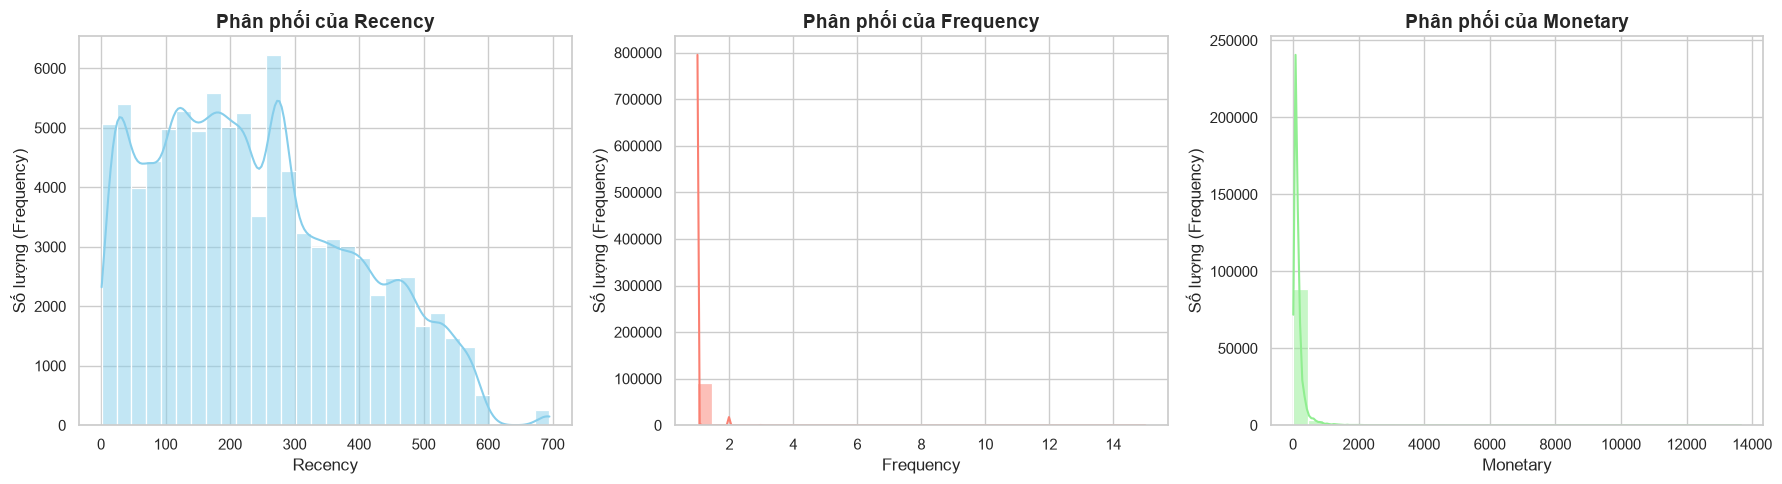

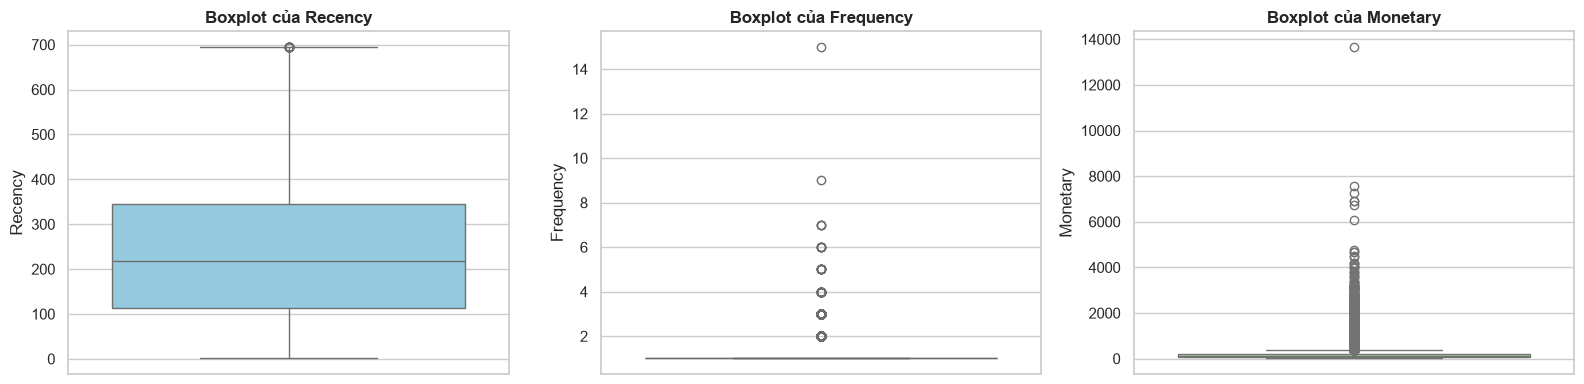

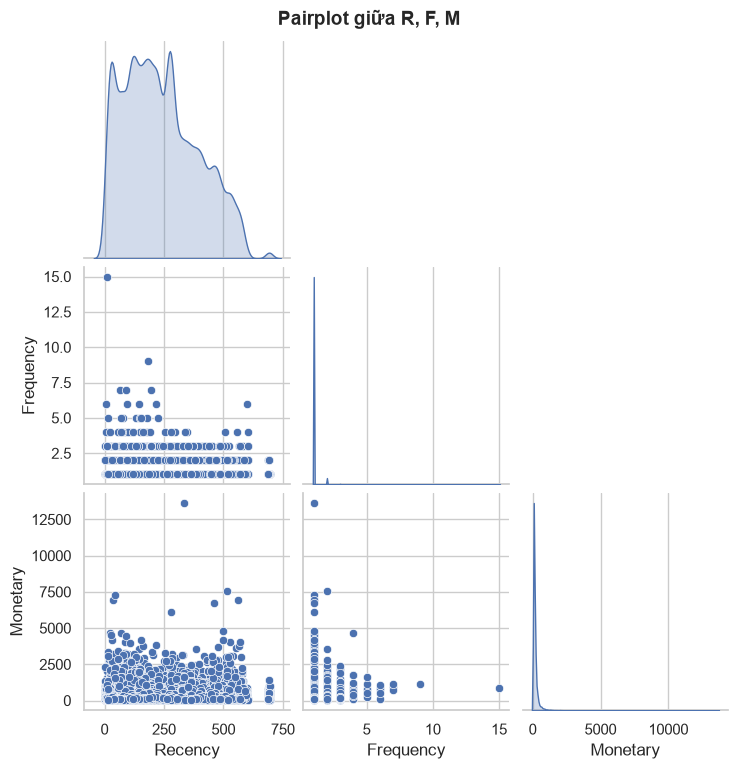

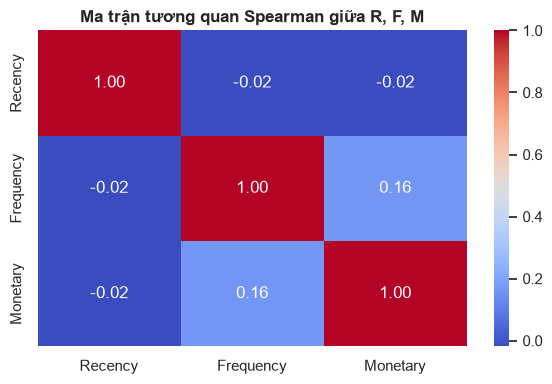

In [6]:
def perform_eda(rfm_df: pd.DataFrame, output_dir: Path = None) -> pd.DataFrame:
    """Thực hiện EDA tập trung vào ba chỉ số R, F, M, in thống kê và trực quan hóa."""
    cols = ["Recency", "Frequency", "Monetary"]
    colors = ["skyblue", "salmon", "lightgreen"]

    print("=" * 70)
    print("GIAI ĐOẠN EDA: PHÂN TÍCH KHÁM PHÁ CÁC CHỈ SỐ R, F, M THÔ")
    print("=" * 70)

    # 1. Thống kê mô tả
    desc = rfm_df[cols].describe().T
    print("\n[1] Thống kê mô tả R, F, M:")
    print(desc.to_string())

    # 2. Phân phối Histplot
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        sns.histplot(data=rfm_df, x=col, kde=True, color=colors[i], ax=axes[i], bins=30)
        axes[i].set_title(f"Phân phối của {col}", fontsize=14, fontweight="bold")
        axes[i].set_xlabel(col, fontsize=12)
        axes[i].set_ylabel("Số lượng (Frequency)", fontsize=12)
    plt.tight_layout()
    if output_dir:
        fig.savefig(output_dir / "eda_01_rfm_distributions.png", dpi=300, bbox_inches="tight")
    plt.show()

    # 3. Boxplot ngoại lệ
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for i, col in enumerate(cols):
        sns.boxplot(data=rfm_df, y=col, ax=axes[i], color=colors[i])
        axes[i].set_title(f"Boxplot của {col}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    if output_dir:
        fig.savefig(output_dir / "eda_02_rfm_boxplots.png", dpi=300, bbox_inches="tight")
    plt.show()

    # 4. Pairplot
    pairplot_fig = sns.pairplot(rfm_df[cols], diag_kind="kde", corner=True)
    pairplot_fig.fig.suptitle("Pairplot giữa R, F, M", y=1.02, fontsize=14, fontweight="bold")
    if output_dir:
        pairplot_fig.savefig(output_dir / "eda_03_rfm_pairplot.png", dpi=300, bbox_inches="tight")
    plt.show()

    # 5. Correlation Heatmap (Spearman)
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(rfm_df[cols].corr(method="spearman"), annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
    ax.set_title("Ma trận tương quan Spearman giữa R, F, M", fontsize=12, fontweight="bold")
    plt.tight_layout()
    if output_dir:
        fig.savefig(output_dir / "eda_04_rfm_spearman_correlation.png", dpi=300, bbox_inches="tight")
    plt.show()

    return desc


# Gọi EDA trực tiếp trong Notebook
desc_stats = perform_eda(rfm_raw, output_dir=PROJECT_ROOT / "reports" / "figures")

Đã tính RFM thô cho 93,357 khách hàng duy nhất.
Ngưỡng P99 của Monetary: 1,097.06
Số khách hàng bị chặn trần: 934
Tỷ lệ bị chặn trần: 1.00%
Đã lưu biểu đồ tại: D:\Machine Learning\PROJECT REPO\reports\figures\01_monetary_boxplot_capping.png


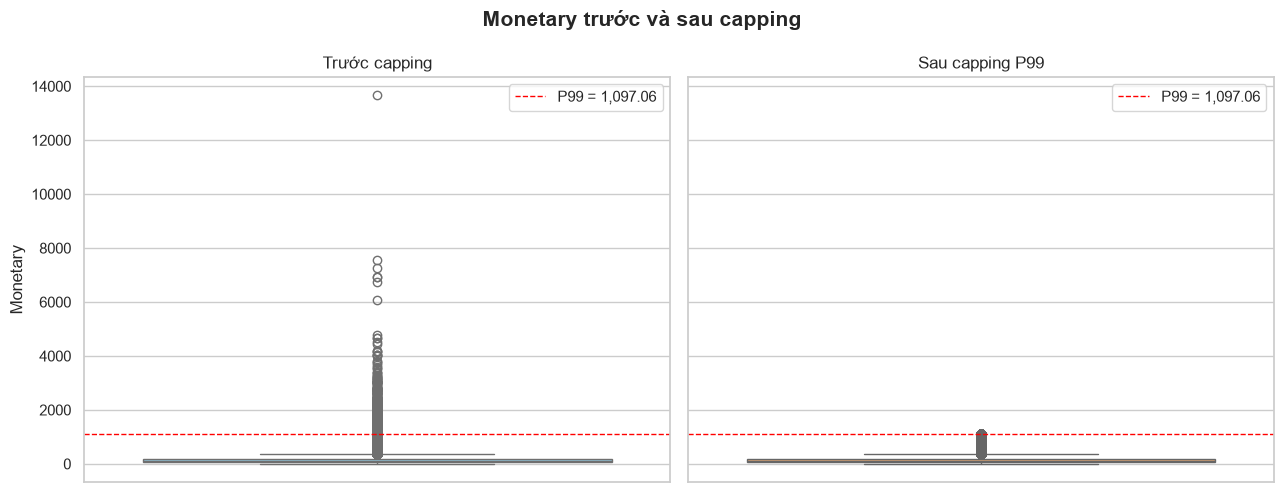

Đã biến đổi Frequency bằng log1p(F).
Đã biến đổi Monetary bằng log(M).
Đã lưu biểu đồ tại: D:\Machine Learning\PROJECT REPO\reports\figures\02_frequency_monetary_histogram_log.png


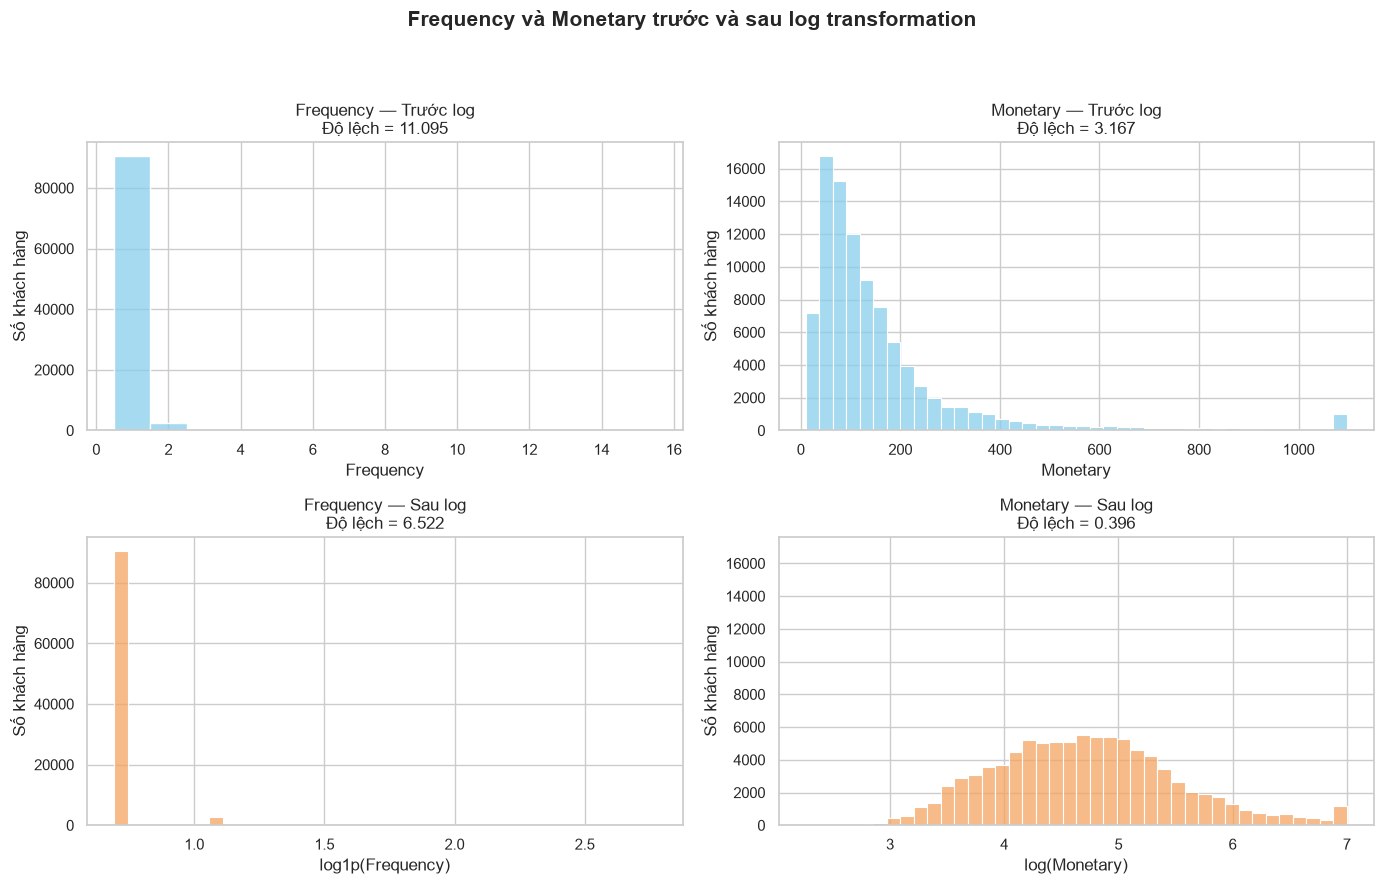

Đã chuẩn hóa toàn bộ 93,357 khách hàng với 3 đặc trưng.
Đã lưu biểu đồ tại: D:\Machine Learning\PROJECT REPO\reports\figures\03_rfm_histogram_standardscaler.png


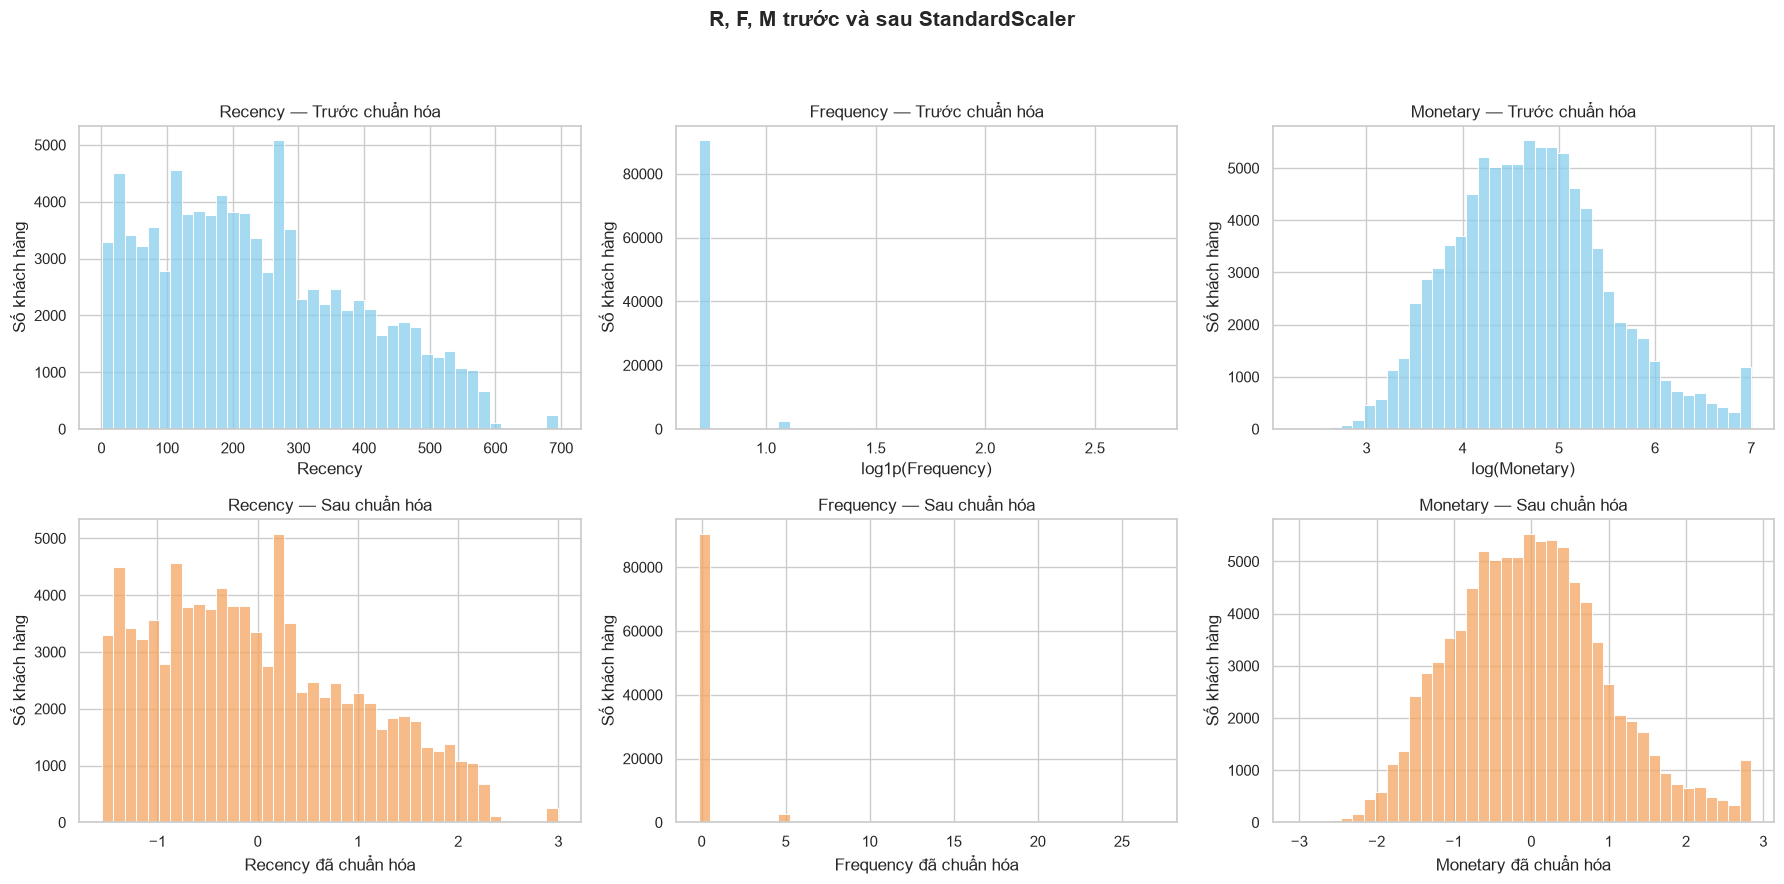

Đã lưu bộ dữ liệu RFM scaled tại: D:\Machine Learning\PROJECT REPO\data\processed\rfm_features_scaled.csv


In [7]:
# Thực hiện toàn bộ pipeline tiền xử lý (Capping -> Log -> Scaling và vẽ ảnh so sánh từng bước)
df_rfm_scaled = processor.preprocess_features(plot=True)

# Lưu bộ dữ liệu hoàn thiện ra file CSV
processor.save_processed_data(
    output_dir=PROJECT_ROOT / "data" / "processed",
    output_filename="rfm_features_scaled.csv"
)